<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 11 · Hierarchies</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A local model fits one forecasting function per series; a global model fits one function to every series stacked into a single table. When the series are related, as weekly harvests from farms growing one crop usually are, the global model pools them: a farm with two seasons of history borrows the shape of a season from farms with five. Pooling needs one preparation step. Each series is divided by its own level, so the model learns shape rather than size, and the forecast is multiplied back afterwards. On ten synthetic panels of 30 farms, one scaled gradient-boosted model brought the mean absolute error to $0.74$ of seasonal naive, against $0.81$ for one model per farm. Most of the gain came from farms with one to three seasons of history. Farms with a differently shaped season and five seasons of history went the other way: there the local models won. Afterwards you should be able to stack and scale a panel, decide whether to give the model a series identifier, forecast a series that has no history yet, and read a backtest to see where local models are worth keeping.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
threadpool_limits(1)  # hundreds of small fits run faster on one thread each
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P, H = 52, 4  # weeks per season; forecast horizon in weeks
TEST = 5 * P  # the sixth season, weeks 260-311, is held out

## Local and global models

A produce business forecasts every farm, every variety and every customer: a **panel** of $N$ related series. A **local** model fits a separate function to each series; a **global** model fits one function to the rows of all of them stacked together:

$$\text{local: } \hat{y}_{i,t+h \mid t} = f_i(\mathbf{x}_{i,t}), \qquad \text{global: } \hat{y}_{i,t+h \mid t} = f(\mathbf{x}_{i,t})$$

where $y_{i,t}$ is the harvest of series $i = 1, \dots, N$ in week $t$ (tonnes per week, t/week), $\hat{y}_{i,t+h \mid t}$ its forecast $h$ weeks after the origin $t$, $\mathbf{x}_{i,t}$ the features of series $i$ known at $t$, and $f_i$ and $f$ the fitted functions. Each row of the table is built as in [Gradient boosting for tabular time series](../forecast/gradient_boosting_for_time_series.ipynb).

One function for every series looks restrictive, but Montero-Manso and Hyndman show that local and global methods can produce the same forecasts without assuming the series are similar, and that a local method's complexity grows with the number of series while a global method's stays constant[^1]. Put simply, a global model learns the shape of a season from every series' seasons, which matters because short histories are common in produce: new plantings, new varieties, new customers.

The panel here is **synthetic**, from a fixed seed: 30 farms of one crop, weekly harvest over six 52-week seasons, the sixth held out. The farms differ in **size** (area and yield per hectare), **timing** (each farm's peak is offset from week 26, and some years are early for everyone), **year** (good and bad years, shared and individual) and **history**: the 27 typical farms have one to five seasons before the held-out one. Three farms have five seasons and a different shape, two flushes 11 weeks either side of the usual peak. Noise is multiplicative, with log-unit shocks of standard deviation $0.12$, $60\%$ of each carried into the next week.

In [2]:
def simulate(seed, n=30, n_odd=3):
    """Synthetic weekly harvest (t/week) for n farms over six seasons."""
    rng = np.random.default_rng(seed)
    t = np.arange(6 * P)
    week, season = t % P, t // P
    year_size = rng.normal(1, 0.10, 6)  # a good or bad year, shared by every farm
    year_shift = rng.normal(0, 1.5, 6)  # an early or late year, shared by every farm
    series, meta = [], []
    for i in range(n):
        odd = i >= n - n_odd
        area = np.exp(rng.normal(np.log(20), 0.8))  # hectares
        peak_yield = np.exp(rng.normal(np.log(1.5), 0.25))  # t/ha/week at the peak
        peak = 26 + rng.normal(0, 3) + year_shift + rng.normal(0, 1, 6)  # peak week, per season
        if odd:  # two flushes, 11 weeks either side of the usual peak
            shape = sum(0.8 * np.exp(-0.5 * ((week - peak[season] + s) / 3.5) ** 2) for s in (-11, 11))
        else:
            shape = np.exp(-0.5 * ((week - peak[season]) / rng.uniform(5, 7)) ** 2)
        size = (year_size * rng.normal(1, 0.10, 6))[season]
        eps = np.zeros(len(t))
        for k in range(1, len(t)):  # AR(1) noise in log units
            eps[k] = 0.6 * eps[k - 1] + rng.normal(0, 0.12)
        y = area * peak_yield * size * (0.1 + shape) * np.exp(eps)
        seasons = 5 if odd else 1 + i % 5  # seasons of history before the held-out one
        keep = t >= TEST - seasons * P
        series.append(pd.DataFrame({"series": i, "t": t[keep], "y": y[keep]}))
        meta.append({"area_ha": area, "seasons": seasons, "kind": "two flushes" if odd else "one peak"})
    return pd.concat(series, ignore_index=True), pd.DataFrame(meta)


panel, meta = simulate(seed=0)
avg = panel[panel.t < TEST].groupby("series").y.mean()
print(f"{len(meta)} series, {len(panel)} series-weeks; mean harvest {avg.min():.1f} to {avg.max():.1f} t/week")

30 series, 6396 series-weeks; mean harvest 1.4 to 36.7 t/week


Average harvests run from $1.4$ to $36.7\text{ t/week}$, a ratio of $36.7/1.4 \approx 26$.

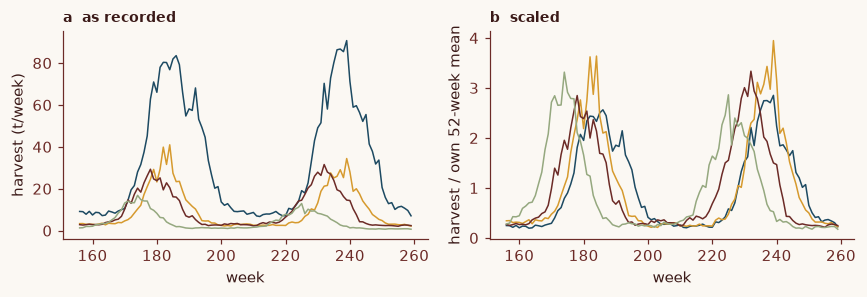

In [3]:
show = meta.index[(meta.seasons == 5) & (meta.kind == "one peak")][:4]
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 2.8))
for i, c in zip(show, [C1, C2, C3, C4]):
    s = panel[panel.series == i].set_index("t").y
    w = s.loc[3 * P : TEST - 1]
    a.plot(w.index, w, color=c, lw=1)
    b.plot(w.index, w / s.rolling(P).mean().loc[w.index], color=c, lw=1)
for ax, title, unit in [(a, "a  as recorded", "harvest (t/week)"), (b, "b  scaled", "harvest / own 52-week mean")]:
    ax.set(xlabel="week", ylabel=unit)
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

<strong>Figure 1 | Different sizes, one shape.</strong> Two training seasons of four farms with five seasons of history. <strong>a</strong>, Harvest as recorded. <strong>b</strong>, The same harvest divided by each farm's trailing 52-week mean.

## Scale, then stack

Each leaf of a boosted tree predicts an average of training targets, so a leaf holding rows from a farm averaging $36.7\text{ t/week}$ and one averaging $1.4$ is wrong for both, and splits go on sorting farms by size instead of learning the season. The fix is to divide each series by its own level, fit the model to the ratio, and multiply back:

$$z_{i,t} = \frac{y_{i,t}}{s_{i,t}}, \qquad s_{i,t} = \frac{1}{52}\sum_{k=0}^{51} y_{i,t-k}, \qquad \hat{y}_{i,t+h \mid t} = s_{i,t}\,\hat{z}_{i,t+h \mid t}$$

where $z_{i,t}$ is the scaled harvest (dimensionless), $s_{i,t}$ the mean of series $i$ over the 52 weeks up to the origin (t/week), and $\hat{z}_{i,t+h \mid t}$ the model's forecast of the scaled target. Lags are divided by the same $s_{i,t}$; Figure 1b is what the model sees.

The window is a whole season, so the level does not depend on where in the season the origin falls, and it ends at the origin: a level over the whole series, held-out season included, is the fitted-transform leak in [Leakage](../leakage/leakage.ipynb). The cost is that a farm contributes training rows only once it has a full season; before that it is forecast entirely from the other farms' shape.

The features, for a horizon of $h = 4$ weeks, are the last four weeks of harvest, the same week of last season, and the week of the season being forecast. A farm in its first season has no "same week last season"; scikit-learn's `HistGradientBoostingRegressor` treats it as missing.

In [4]:
LAGS = ["y_t", "y_t-1", "y_t-2", "y_t-3", "same_week_last_season"]
FEATS = LAGS + ["target_week"]


def rows(panel, h=H):
    """One row per series and origin t: features known at t, target y[t+h]."""
    g = panel.groupby("series").y
    d = panel[["series", "t"]].copy()
    for k in range(4):
        d[LAGS[k]] = g.shift(k)
    d["same_week_last_season"] = g.shift(P - h)  # y[t+h-52], known at t
    d["level"] = g.transform(lambda s: s.rolling(P).mean())  # s_it, trailing 52-week mean
    d["target_week"] = (d.t + h) % P
    d["target_time"] = d.t + h
    d["target"] = g.shift(-h)
    return d.dropna(subset=["y_t-3", "target"])


def scaled(d):
    return d[FEATS].assign(**{c: d[c] / d.level for c in LAGS})


d = rows(panel)
d[d.series == show[0]].dropna().head(3).round(2)

,series,t,y_t,y_t-1,y_t-2,y_t-3,same_week_last_season,level,target_week,target_time,target
779,4,51,9.57,11.13,13.57,16.70,10.14,38.28,3,55,7.00
780,4,52,7.97,9.57,11.13,13.57,8.57,38.27,4,56,8.62
781,4,53,6.29,7.97,9.57,11.13,7.79,38.21,5,57,9.08


Four models share the same untuned settings: **local**, one model per farm on its own raw rows; **global, unscaled**, one model on all farms' raw rows; **global**, the same on scaled rows; and **global + series ID**, which adds the farm's identifier as a categorical feature.

The backtest follows [Backtesting properly](../backtesting/backtesting_properly.ipynb): every week of the held-out season is a target, forecast from an origin four weeks earlier; models are refitted every 13 weeks on targets already observed; and every score sits beside seasonal naive, $\hat{y}_{i,t+h \mid t} = y_{i,t+h-52}$. Production would refit more often; four refits keep the local fits to $30 \times 4 = 120$.

So that the largest farm does not decide the result, each farm's mean absolute error (MAE) is divided by seasonal naive's MAE on the same weeks (below $1$ beats the baseline), and the ratios are combined with a geometric mean, under which halving one farm's error and doubling another's cancel out.

In [5]:
def gbm(**kw):
    return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, min_samples_leaf=10, random_state=0, **kw)


def local(tr, te):
    pred = pd.Series(np.nan, index=te.index)
    for i, g in tr.groupby("series"):
        cols = [c for c in FEATS if g[c].notna().any()]  # one season has no "last season"
        idx = te.index[te.series == i]
        pred[idx] = gbm().fit(g[cols], g.target).predict(te.loc[idx, cols])
    return pred


def global_model(tr, te, scale=True, series_id=False):
    if not scale:
        return gbm().fit(tr[FEATS], tr.target).predict(te[FEATS])
    tr = tr.dropna(subset=["level"])  # the level needs a full season of history
    X, Xte = scaled(tr), scaled(te)
    if series_id:
        X, Xte = X.assign(series=tr.series), Xte.assign(series=te.series)
    model = gbm(categorical_features=["series"] if series_id else None)
    return model.fit(X, tr.target / tr.level).predict(Xte) * te.level  # undo the scaling


METHODS = {
    "local": local,
    "global, unscaled": lambda tr, te: global_model(tr, te, scale=False),
    "global": global_model,
    "global + series ID": lambda tr, te: global_model(tr, te, series_id=True),
}


def backtest(d, refit_every=13):
    test = d[d.target_time >= TEST].copy()
    for start in range(TEST, TEST + P, refit_every):
        block = test[(test.target_time >= start) & (test.target_time < start + refit_every)]
        tr = d[d.target_time <= start - H]  # targets already observed at the block's first origin
        for name, method in METHODS.items():
            test.loc[block.index, name] = method(tr, block)
    test["seasonal naive"] = test.same_week_last_season
    return test


def relative_mae(bt):
    """Each method's MAE per series, divided by seasonal naive's MAE on the same weeks."""
    mae = bt[["seasonal naive", *METHODS]].sub(bt.target, axis=0).abs().groupby(bt.series).mean()
    return mae[list(METHODS)].div(mae["seasonal naive"], axis=0), mae["seasonal naive"]


def gmean(x):
    return np.exp(np.log(x).mean())

In [6]:
rel, naive_mae = relative_mae(backtest(d))
print("geometric mean over 30 series:", gmean(rel).round(2).to_dict())
print(f"local beats global on {(rel['local'] < rel['global']).sum()} of {len(rel)} series")
rel.groupby([meta.kind, meta.seasons]).agg(gmean).round(2)

geometric mean over 30 series: {'local': 0.88, 'global, unscaled': 0.88, 'global': 0.79, 'global + series ID': 0.81}
local beats global on 9 of 30 series


local  global, unscaled  global  global + series ID
kind        seasons                                                     
one peak    1         1.28              1.10    0.86                0.87
            2         0.84              0.65    0.66                0.82
            3         0.79              0.89    0.78                0.77
            4         0.70              0.79    0.76                0.75
            5         0.91              0.95    1.00                0.88
two flushes 5         0.73              1.02    0.72                0.74

## Which wins, and when

On this panel the scaled global model scores $0.79$ of seasonal naive, against $0.88$ for both the local and the unscaled global models. It is not a clean sweep: local is better on 9 of the 30 farms, and the two-flush farms score $0.73$ local against $0.72$ global. With five or six farms per row, one season is too noisy to judge, so the experiment is repeated on ten independently simulated panels, 300 farms in all:

In [7]:
runs = []
for seed in range(10):
    p, m = simulate(seed)
    runs.append(relative_mae(backtest(rows(p)))[0].join(m).assign(seed=seed))
runs = pd.concat(runs)
history = np.where(runs.kind == "two flushes", "5, two flushes", runs.seasons.astype(str))
by_history = runs.groupby(history)[list(METHODS)].agg(gmean)
print("geometric mean over 300 series:", gmean(runs[list(METHODS)]).round(2).to_dict())
by_history.round(2)

geometric mean over 300 series: {'local': 0.81, 'global, unscaled': 0.83, 'global': 0.74, 'global + series ID': 0.74}


,local,"global, unscaled",global,global + series ID
1,1.02,0.89,0.80,0.80
2,0.84,0.78,0.71,0.77
3,0.84,0.83,0.71,0.71
4,0.76,0.81,0.77,0.76
5,0.73,0.82,0.73,0.69
"5, two flushes",0.61,0.87,0.67,0.64


Over 300 farms the local models score $0.81$, the unscaled global model $0.83$ and the scaled global model $0.74$, with or without the identifier. Without scaling, pooling gained nothing.

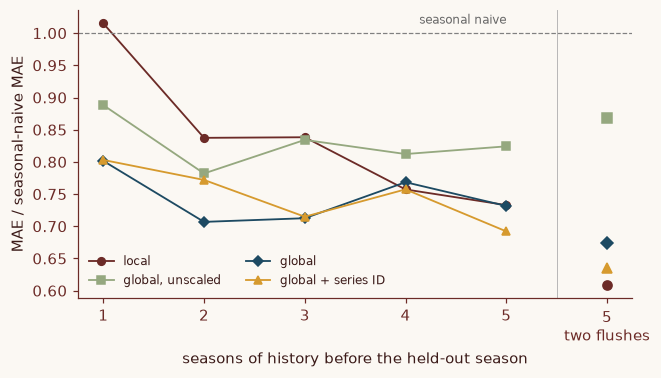

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(by_history))
for (name, col), c, mk in zip(by_history.items(), [C3, C4, C1, C2], "osD^"):
    ax.plot(x[:-1], col.iloc[:-1], color=c, marker=mk, ms=5, lw=1.2, label=name)
    ax.plot(x[-1], col.iloc[-1], color=c, marker=mk, ms=6, ls="none")  # a different kind of series
ax.axvline(x[-1] - 0.5, color="0.7", lw=0.6)
ax.axhline(1, color="0.5", lw=0.8, ls="--")
ax.text(x[-2], 1.01, "seasonal naive", ha="right", va="bottom", fontsize=8, color="0.4")
ax.set_xticks(x, [*by_history.index[:-1], "5\ntwo flushes"])
ax.set(xlabel="seasons of history before the held-out season", ylabel="MAE / seasonal-naive MAE")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

<strong>Figure 2 | Pooling helps most where a farm's own history is short.</strong> Geometric mean, over ten synthetic panels, of each model's MAE divided by seasonal naive's on the same farm and weeks, by seasons of history. Right of the vertical line: the three two-flush farms per panel. Below the dashed line beats seasonal naive.

The gain follows history length. With one season, the local model learns from one season of its own and does worse than seasonal naive ($1.02$); the global model scores $0.80$. With two or three seasons, global leads $0.71$ to $0.84$. By four seasons they tie (local $0.76$, global $0.77$), and at five both score $0.73$. All models share one untuned configuration, which may suit a global model fitted on thousands of rows better than a local one fitted on a few dozen, so the local scores at short histories are, if anything, a little pessimistic.

The two-flush farms are where local wins, $0.61$ against $0.67$: their season truly differs from the other 27, they have five seasons to learn it from, and the global model's week-of-season splits are fitted mostly to one-peak farms. Pooling helps a series only as far as it resembles the others. With real data there is no second panel, so read the backtest per series, over as many held-out seasons as exist, before moving a series to a local model or to a global model of its own kind.

## Series IDs and cold start

A series identifier lets the trees carve local corrections into a global model. It helped where there was data to correct, $0.69$ against $0.73$ for five-season farms and $0.64$ against $0.67$ for two-flush farms, and hurt where there was not, $0.77$ against $0.71$ for two-season farms. Three costs do not show in the scores:

- **It does not transfer.** scikit-learn treats an identifier unseen in training as missing, so it adds nothing for a new series.
- **It brings back local complexity.** One-hot encoded in a linear model, it adds one coefficient per series.
- **Target-encoding it is a fitted transform**, to be fitted inside the training window like any other ([Leakage](../leakage/leakage.ipynb)).

Features that say *why* series differ, such as variety, region, area or sales channel, still mean something for a new series. Prefer them.

A new farm is **cold start**: no lags, no level, no seasonal naive. Its planted area is known before the first harvest, so the simplest forecast learns harvest per hectare by week of season from the other farms and multiplies by the new farm's area. Each farm is treated in turn as new:

In [9]:
def cold_start(panel, meta, i):
    """Series i's held-out season with no history at all: its area x a shape learned from the others."""
    tr = panel[(panel.series != i) & (panel.t < TEST)]
    per_ha = tr.y / meta.area_ha.loc[tr.series].to_numpy()  # t/ha/week
    model = gbm().fit((tr.t % P).to_frame("week"), per_ha)
    te = panel[(panel.series == i) & (panel.t >= TEST)]
    return np.abs(model.predict((te.t % P).to_frame("week")) * meta.area_ha[i] - te.y).mean()


rel["cold start"] = [cold_start(panel, meta, i) / naive_mae[i] for i in meta.index]
rel.groupby(meta.kind)[["cold start", "global", "local"]].agg(gmean).round(2)

,cold start,global,local
kind,,,
one peak,1.76,0.80,0.90
two flushes,3.10,0.72,0.73


For typical farms the cold-start error is $1.76$ times seasonal naive's, against $0.80$ for the scaled global model on the same farms: $1.76/0.80 \approx 2.2$ times the error. Area cannot reveal a farm's yield per hectare or how early it peaks. For two-flush farms the ratio is $3.10$, because a cold-start forecast assumes the new series is typical. Use it as a placeholder until the series has a level of its own.

One problem is left. The business also needs totals by region, variety and customer, and totals forecast separately will not equal the sum of the farm forecasts. The M5 competition had this structure, 42,840 hierarchical series, and asked for forecasts of the 30,490 at the lowest level, which could be summed to estimate the levels above[^2]. Making forecasts at every level of a hierarchy add up is the problem of coherence.

## Key takeaways

- A global model fits one function to all series stacked and pools their information; that matters most for short histories.
- Scale each series by its own level, computed as of the origin over a whole season, and multiply back. Unscaled, pooling gained nothing here.
- Compare per series against seasonal naive, combined by geometric mean. With one to three seasons the global model clearly won; with five, and a shape of their own, local models won.
- Series identifiers help long histories, hurt short ones and cannot help a new series; descriptive features transfer. A cold-start forecast assumes the new series is typical.

## References

[^1]: Montero-Manso, P. & Hyndman, R. J. Principles and algorithms for forecasting groups of time series: locality and globality. *Int. J. Forecast.* **37**, 1632–1653 (2021). https://doi.org/10.1016/j.ijforecast.2021.03.004
[^2]: Makridakis, S., Spiliotis, E. & Assimakopoulos, V. M5 accuracy competition: results, findings, and conclusions. *Int. J. Forecast.* **38**, 1346–1364 (2022). https://doi.org/10.1016/j.ijforecast.2021.11.013

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/hierarchical-reconciliation/hierarchical_reconciliation.html"><span>Previous</span>Hierarchical reconciliation</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/ets-and-arima/ets_and_arima.html"><span>Next</span>ETS and ARIMA</a></div>
<!-- CURRICULUM_FOOTER_END -->